![fake-news-hero-img](fake-news-hero-img.jpg)

# 📰 Fake News Detection Project

Ce projet consiste à détecter automatiquement les fausses informations (Fake News) à l'aide de techniques de Machine Learning et de traitement du langage naturel (NLP).

Avec l’augmentation des informations en ligne, il devient essentiel de distinguer les vraies informations des fausses.

## Objectif

L’objectif est de construire un modèle capable de classifier une information en :
- Fake News (0)
- True News (1)

#  Chargement des données

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
from sklearn.metrics import classification_report
import re
import string
from wordcloud import WordCloud
import matplotlib.pyplot as plt

In [2]:
import pandas as pd

df_fake = pd.read_csv("Fake.csv")
df_true = pd.read_csv("True.csv")

In [3]:
df_fake.head()

,title,text,subject,date
0,Donald Trump Sends Out Embarrassing New Year’...,Donald Trump just couldn t wish all Americans ...,News,"December 31, 2017"
1,Drunk Bragging Trump Staffer Started Russian ...,House Intelligence Committee Chairman Devin Nu...,News,"December 31, 2017"
2,Sheriff David Clarke Becomes An Internet Joke...,"On Friday, it was revealed that former Milwauk...",News,"December 30, 2017"
3,Trump Is So Obsessed He Even Has Obama’s Name...,"On Christmas day, Donald Trump announced that ...",News,"December 29, 2017"
4,Pope Francis Just Called Out Donald Trump Dur...,Pope Francis used his annual Christmas Day mes...,News,"December 25, 2017"


In [4]:
df_true.head()

,title,text,subject,date
0,"As U.S. budget fight looms, Republicans flip t...",WASHINGTON (Reuters) - The head of a conservat...,politicsNews,"December 31, 2017"
1,U.S. military to accept transgender recruits o...,WASHINGTON (Reuters) - Transgender people will...,politicsNews,"December 29, 2017"
2,Senior U.S. Republican senator: 'Let Mr. Muell...,WASHINGTON (Reuters) - The special counsel inv...,politicsNews,"December 31, 2017"
3,FBI Russia probe helped by Australian diplomat...,WASHINGTON (Reuters) - Trump campaign adviser ...,politicsNews,"December 30, 2017"
4,Trump wants Postal Service to charge 'much mor...,SEATTLE/WASHINGTON (Reuters) - President Donal...,politicsNews,"December 29, 2017"


In [5]:
df_fake.head()

,title,text,subject,date
0,Donald Trump Sends Out Embarrassing New Year’...,Donald Trump just couldn t wish all Americans ...,News,"December 31, 2017"
1,Drunk Bragging Trump Staffer Started Russian ...,House Intelligence Committee Chairman Devin Nu...,News,"December 31, 2017"
2,Sheriff David Clarke Becomes An Internet Joke...,"On Friday, it was revealed that former Milwauk...",News,"December 30, 2017"
3,Trump Is So Obsessed He Even Has Obama’s Name...,"On Christmas day, Donald Trump announced that ...",News,"December 29, 2017"
4,Pope Francis Just Called Out Donald Trump Dur...,Pope Francis used his annual Christmas Day mes...,News,"December 25, 2017"


# Ajouter les labels

In [7]:
df_fake["class"] = 0
df_true["class"] = 1

## Suppression des 10 dernières lignes pour les tests manuels

In [9]:

df_fake_manual_testing = df_fake.tail(10)
for i in range(23480,23470,-1):
    df_fake.drop([i], axis = 0, inplace = True)
    
    
df_true_manual_testing = df_true.tail(10)
for i in range(21416,21406,-1):
    df_true.drop([i], axis = 0, inplace = True)

In [10]:
df_fake_manual_testing.head(10)

,title,text,subject,date,class
23471,Seven Iranians freed in the prisoner swap have...,"21st Century Wire says This week, the historic...",Middle-east,"January 20, 2016",0
23472,#Hashtag Hell & The Fake Left,By Dady Chery and Gilbert MercierAll writers ...,Middle-east,"January 19, 2016",0
23473,Astroturfing: Journalist Reveals Brainwashing ...,Vic Bishop Waking TimesOur reality is carefull...,Middle-east,"January 19, 2016",0
23474,The New American Century: An Era of Fraud,Paul Craig RobertsIn the last years of the 20t...,Middle-east,"January 19, 2016",0
23475,Hillary Clinton: ‘Israel First’ (and no peace ...,Robert Fantina CounterpunchAlthough the United...,Middle-east,"January 18, 2016",0
23476,McPain: John McCain Furious That Iran Treated ...,21st Century Wire says As 21WIRE reported earl...,Middle-east,"January 16, 2016",0
23477,JUSTICE? Yahoo Settles E-mail Privacy Class-ac...,21st Century Wire says It s a familiar theme. ...,Middle-east,"January 16, 2016",0
23478,Sunnistan: US and Allied ‘Safe Zone’ Plan to T...,Patrick Henningsen 21st Century WireRemember ...,Middle-east,"January 15, 2016",0
23479,How to Blow $700 Million: Al Jazeera America F...,21st Century Wire says Al Jazeera America will...,Middle-east,"January 14, 2016",0
23480,10 U.S. Navy Sailors Held by Iranian Military ...,21st Century Wire says As 21WIRE predicted in ...,Middle-east,"January 12, 2016",0


In [11]:
df_true_manual_testing.head(10)

,title,text,subject,date,class
21407,"Mata Pires, owner of embattled Brazil builder ...","SAO PAULO (Reuters) - Cesar Mata Pires, the ow...",worldnews,"August 22, 2017",1
21408,"U.S., North Korea clash at U.N. forum over nuc...",GENEVA (Reuters) - North Korea and the United ...,worldnews,"August 22, 2017",1
21409,"U.S., North Korea clash at U.N. arms forum on ...",GENEVA (Reuters) - North Korea and the United ...,worldnews,"August 22, 2017",1
21410,Headless torso could belong to submarine journ...,COPENHAGEN (Reuters) - Danish police said on T...,worldnews,"August 22, 2017",1
21411,North Korea shipments to Syria chemical arms a...,UNITED NATIONS (Reuters) - Two North Korean sh...,worldnews,"August 21, 2017",1
21412,'Fully committed' NATO backs new U.S. approach...,BRUSSELS (Reuters) - NATO allies on Tuesday we...,worldnews,"August 22, 2017",1
21413,LexisNexis withdrew two products from Chinese ...,"LONDON (Reuters) - LexisNexis, a provider of l...",worldnews,"August 22, 2017",1
21414,Minsk cultural hub becomes haven from authorities,MINSK (Reuters) - In the shadow of disused Sov...,worldnews,"August 22, 2017",1
21415,Vatican upbeat on possibility of Pope Francis ...,MOSCOW (Reuters) - Vatican Secretary of State ...,worldnews,"August 22, 2017",1
21416,Indonesia to buy $1.14 billion worth of Russia...,JAKARTA (Reuters) - Indonesia will buy 11 Sukh...,worldnews,"August 22, 2017",1


# Fusion des datasets

In [13]:
df = pd.concat([df_fake, df_true])
df = df.sample(frac=1, random_state=42)
df.reset_index(drop=True, inplace=True)

# Aperçu des données

In [15]:
df.head()

,title,text,subject,date,class
0,White House Officials Admit That Trump LIED A...,Donald Trump has been bragging about his inaug...,News,"January 21, 2017",0
1,Egypt says bombs militants responsible for Wes...,CAIRO (Reuters) - Egypt s air force killed a l...,worldnews,"October 31, 2017",1
2,OUTRAGEOUS! Intimidation of Citizens Opposed t...,"A press release by Bernards Township, NJ is pr...",Government News,"Mar 28, 2017",0
3,AS TRUMP’S POPULARITY SOARS ABROAD…Village In ...,President Donald Trump welcomed India s Prime ...,left-news,"Jun 27, 2017",0
4,"Lebanon ex-PM meets French, UK, EU, U.S. diplo...","BEIRUT (Reuters) - Saad al-Hariri, who resigne...",worldnews,"November 9, 2017",1


In [16]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 44878 entries, 0 to 44877
Data columns (total 5 columns):
 #   Column   Non-Null Count  Dtype 
---  ------   --------------  ----- 
 0   title    44878 non-null  object
 1   text     44878 non-null  object
 2   subject  44878 non-null  object
 3   date     44878 non-null  object
 4   class    44878 non-null  int64 
dtypes: int64(1), object(4)
memory usage: 1.7+ MB


In [17]:
df.describe()

,class
count,44878.000000
mean,0.477004
std,0.499476
min,0.000000
25%,0.000000
50%,0.000000
75%,1.000000
max,1.000000


# Distribution des classes

In [19]:
df["class"].value_counts()

class
0    23471
1    21407
Name: count, dtype: int64

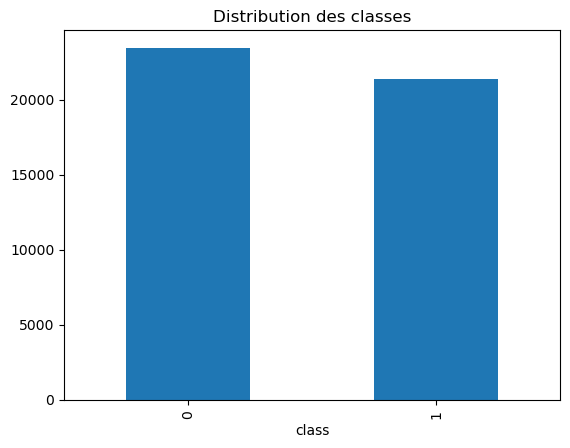

In [20]:
import matplotlib.pyplot as plt

df["class"].value_counts().plot(kind='bar')
plt.title("Distribution des classes")
plt.show()

## Distribution des classes

Le graphique montre la répartition des classes dans le dataset.

- La classe 0 (Fake News) contient légèrement plus d'exemples
- La classe 1 (True News) est aussi bien représentée

 On observe que les données sont relativement équilibrées, ce qui est favorable pour l'entraînement des modèles de Machine Learning.

In [22]:
df.isnull().sum()

title      0
text       0
subject    0
date       0
class      0
dtype: int64

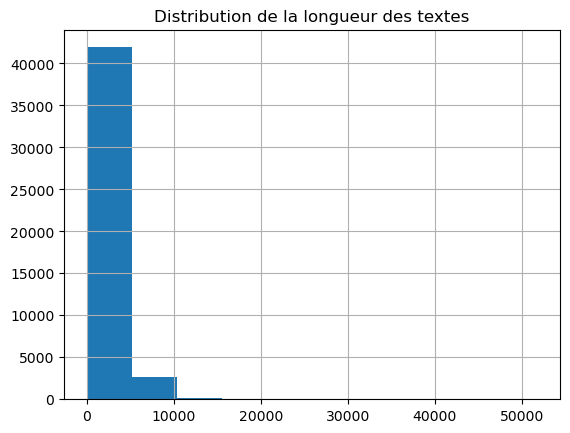

In [23]:
df["length"] = df["text"].apply(len)

df["length"].hist()
plt.title("Distribution de la longueur des textes")
plt.show()

## Distribution de la longueur des textes

L’histogramme montre que la majorité des textes ont une longueur relativement courte.

Cependant, on observe la présence de quelques textes très longs (valeurs extrêmes), ce qui rend la distribution asymétrique.

Cela peut influencer les modèles de Machine Learning, car les textes longs peuvent contenir plus d’informations.

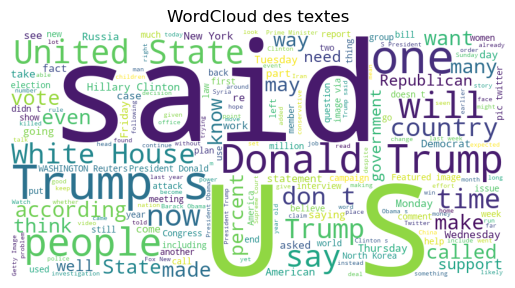

In [25]:
text = " ".join(df["text"].astype(str))

wordcloud = WordCloud(width=800, height=400, background_color='white').generate(text)

plt.imshow(wordcloud)
plt.axis("off")
plt.title("WordCloud des textes")
plt.show()

# Création d'une fonction pour traiter les textes

In [27]:
import re
import string

def wordopt(text):
    text = text.lower()
    text = re.sub(r'\[.*?\]', '', text)
    text = re.sub(r"\W", " ", text) 
    text = re.sub(r'https?://\S+|www\.\S+', '', text)
    text = re.sub(r'<.*?>+', '', text)
    text = re.sub(r'[%s]' % re.escape(string.punctuation), '', text)
    text = re.sub(r'\n', '', text)
    text = re.sub(r'\w*\d\w*', '', text)
    return text

 Nous avons nettoyé les textes en supprimant la ponctuation, les chiffres et en convertissant en minuscules afin de faciliter l’analyse.

## Suppression des colonnes inutiles

In [35]:
df = df.drop(["title", "subject","date"], axis = 1)

## Séparation X et y

In [37]:
X = df["text"]
y = df["class"]

## Train / Test Split

In [40]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42
)

## Vectorisation (TF-IDF)

Transformer texte → nombres

In [42]:
from sklearn.feature_extraction.text import TfidfVectorizer

vectorizer = TfidfVectorizer(max_features=5000)

X_train = vectorizer.fit_transform(X_train)
X_test = vectorizer.transform(X_test)

Nous avons utilisé TF-IDF pour transformer les textes en vecteurs numériques exploitables par les modèles.